Writing

# RQ1 — Can Planning-Time Characteristics Predict Subsequent SATD?

## Research Question

**Can characteristics available during issue planning help distinguish issues that will eventually be classified as Self-Admitted Technical Debt (SATD) from those that will not?**

## Key Finding

Planning-time characteristics show **statistically significant but practically limited ability to distinguish SATD from non-SATD issues**. Issue type and issue age are the most informative characteristics, while the recorded Story Point estimate provides virtually no predictive value. Story Points represent a team's relative estimate of work size or effort; they are not a direct measure of a user story's inherent complexity. However, models trained on these characteristics perform poorly when applied to unseen projects, limiting their usefulness as standalone SATD prediction tools.

## Dataset Overview

The analysis covers **9,507 issues across 25 projects**.

- **2,128 issues (22.38%)** were classified as SATD.
- **7,379 issues (77.62%)** were classified as non-SATD.

## Main Findings

### 1\. Issue type is the strongest categorical indicator

Issue type shows the strongest association with subsequent SATD classification (Cramér's V = 0.104, Holm-adjusted _p_ \< 0.001).

Documentation issues have **3.15 times the adjusted odds of SATD** compared with technical-work issues (95% CI: 2.25–4.40). This makes issue type a potentially useful signal for identifying issues that may later involve technical debt.

However, the effect remains modest overall, so issue type alone cannot reliably identify SATD issues.

### 2\. Older issues are more likely to become SATD

Issues eventually classified as SATD tend to be older when the sprint begins:

- **SATD issues:** median age of 34.70 days
- **Non-SATD issues:** median age of 17.81 days

The difference is small to moderate in magnitude (Cliff's δ = 0.187). After adjustment, each standard-deviation increase in log-transformed issue age is associated with **21.9% higher odds of SATD** (adjusted OR = 1.219, 95% CI: 1.084–1.371).

This suggests that issue age may provide a useful warning signal, although it does not establish that older issues cause technical debt.

### 3\. Priority has a weak association with SATD

Issue priority is statistically associated with subsequent SATD classification, but the relationship is weak (Cramér's V = 0.063).

Although priority may contribute some information, its standalone value for distinguishing SATD from non-SATD issues is limited.

### 4\. Recorded Story Point size provides no meaningful signal

The relative recorded Story Point estimate does not distinguish SATD from non-SATD issues. Here, this variable represents estimated work size or effort relative to other issues in the same project. It does **not** measure the inherent technical or cognitive complexity of a user story:

- Statistical test: _p_ = 0.529
- Effect size: Cliff's δ = −0.011
- Adjusted odds ratio: 1.000, _p_ = 0.996

These results provide no evidence that the recorded relative Story Point estimate is useful for distinguishing eventual SATD classification in this analysis. They do not show that user-story complexity is unrelated to SATD, because complexity was not measured directly.

## Predictive Performance on Unseen Projects

To assess practical usefulness, logistic regression and XGBoost were evaluated on projects not used for training.

| Evaluation metric | Logistic regression | XGBoost |
| --- | --- | --- |
| Out-of-project ROC-AUC | 0.566 (95% project-bootstrap CI: 0.509–0.620) | 0.586 (0.537–0.630) |
| Out-of-project PR-AUC | 0.275 (0.210–0.339) | 0.295 (0.221–0.365) |
| Precision in highest-risk 10% | 32.81% | 35.33% |
| Recall in highest-risk 10% | 14.66% | 15.79% |
| Lift in highest-risk 10% | 1.47× | 1.58× |

XGBoost performs better than logistic regression, but **both models have limited predictive ability**. The confidence intervals come from 2,000 project-cluster bootstrap resamples, so they reflect uncertainty from variation between projects rather than treating all issues as independent.

For context, an ROC-AUC of 0.5 represents chance-level ranking. XGBoost's ROC-AUC of 0.586 indicates only modest discrimination between SATD and non-SATD issues.

The highest-risk decile identified by XGBoost contains **951 issues**, of which **336 are SATD-labelled**. Its SATD rate is **35.33%**, compared with the overall rate of 22.38%: a **1.58× lift**. However, it captures only **15.79% of all SATD-labelled issues**, so more than four-fifths are missed.

This enrichment could help teams prioritize a subset of issues for review. Nevertheless, most SATD issues remain unidentified, and the results do not support using the model as a reliable standalone warning system.

## Overall Conclusion

**Planning-time characteristics offer limited value for anticipating subsequent SATD.** Issue type—particularly documentation-related work—and issue age provide the clearest signals. Priority contributes only a weak association, while the recorded relative Story Point estimate shows no meaningful relationship. This finding concerns estimated work size, not user-story complexity itself.

Despite these associations, predictive performance on unseen projects remains weak. Planning-time characteristics may therefore support **risk prioritization and early review**, but they are insufficient for reliably classifying which issues will eventually be SATD.

These findings describe statistical associations and predictive performance; **they do not establish causal relationships**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from pathlib import Path

DATA_PATH = "rq1_planning_dataset.csv"
OUTPUT_DIR = Path("rq1_results")
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print(df.head())
print("\nColumns:")
print(df.columns.tolist())

Shape: (9507, 26)
   issue_id issue_key  project_id  sprint_id             sprint_start  \
0      2457   XD-1350           1         44  2014-03-04 20:30:13.000   
1      2458   XD-1349           1         44  2014-03-04 20:30:13.000   
2      2459   XD-1348           1         41  2014-04-17 21:00:15.000   
3      2462   XD-1345           1         44  2014-03-04 20:30:13.000   
4      2463   XD-1344           1         40  2014-04-30 22:50:46.000   

                sprint_end planning_priority priority_group  \
0  2014-03-18 19:30:00.000             Major           HIGH   
1  2014-03-18 19:30:00.000             Minor            LOW   
2  2014-04-30 21:00:00.000             Minor            LOW   
3  2014-03-18 19:30:00.000             Minor            LOW   
4  2014-05-21 22:50:00.000             Minor            LOW   

  planning_issue_type issue_type_group  ...  estimated_issue_count  \
0               Story          FEATURE  ...                     16   
1               Story   

In [2]:
df["is_satd"] = pd.to_numeric(
    df["is_satd"],
    errors="coerce"
)

df = df[df["is_satd"].isin([0, 1])].copy()

df["is_satd"] = df["is_satd"].astype(int)

print("\nSATD distribution:")
print(df["is_satd"].value_counts())

print("\nSATD percentage:")
print(
    df["is_satd"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


SATD distribution:
is_satd
0    7379
1    2128
Name: count, dtype: int64

SATD percentage:
is_satd
0    77.62
1    22.38
Name: proportion, dtype: float64


In [3]:
print("\nMissing values:")
missing = (
    df.isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(missing.head(30))


Missing values:
project_sp_percentile             30.314505
planning_priority                 14.063322
sprint_avg_story_points           13.253392
sprint_median_story_points        13.253392
sprint_total_story_points         13.253392
planning_story_point               0.031556
issue_key                          0.000000
project_id                         0.000000
sprint_start                       0.000000
issue_id                           0.000000
issue_type_group                   0.000000
planning_issue_type                0.000000
priority_group                     0.000000
sprint_end                         0.000000
sprint_id                          0.000000
issue_age_days_at_sprint_start     0.000000
relative_story_point_group         0.000000
story_point_missing_or_zero        0.000000
estimated_issue_count              0.000000
sprint_issue_count                 0.000000
urgent_issue_count                 0.000000
urgent_issue_ratio                 0.000000
is_satd        

In [4]:
print("Unique projects:", df["project_id"].nunique())
print("Unique sprints:", df["sprint_id"].nunique())
print("Unique issues:", df["issue_id"].nunique())

Unique projects: 25
Unique sprints: 1732
Unique issues: 9507


In [5]:
duplicates = df["issue_id"].duplicated().sum()

print("Duplicate issues:", duplicates)

Duplicate issues: 0


In [6]:
# -----------------------------------------
# Sprint-level workload normalization
# -----------------------------------------

sprint_load = (
    df[
        [
            "project_id",
            "sprint_id",
            "sprint_total_story_points"
        ]
    ]
    .drop_duplicates(subset=["project_id", "sprint_id"])
    .copy()
)

sprint_load["sprint_sp_load_percentile"] = (
    sprint_load
    .groupby("project_id")["sprint_total_story_points"]
    .rank(pct=True)
)

df = df.drop(
    columns=["sprint_sp_load_percentile"],
    errors="ignore"
).merge(
    sprint_load[
        [
            "project_id",
            "sprint_id",
            "sprint_sp_load_percentile"
        ]
    ],
    on=["project_id", "sprint_id"],
    how="left",
    validate="many_to_one"
)


In [7]:
df["log_issue_age"] = np.log1p(
    df["issue_age_days_at_sprint_start"]
    .clip(lower=0)
)

df["log_sprint_issue_count"] = np.log1p(
    df["sprint_issue_count"]
    .clip(lower=0)
)

In [8]:
overall_satd_rate = df["is_satd"].mean()

print(
    f"Overall SATD prevalence: "
    f"{overall_satd_rate:.4f} "
    f"({overall_satd_rate * 100:.2f}%)"
)

Overall SATD prevalence: 0.2238 (22.38%)


In [9]:
priority_summary = (
    df.groupby("priority_group")
    .agg(
        total_issues=("issue_id", "count"),
        satd_issues=("is_satd", "sum"),
        satd_rate=("is_satd", "mean")
    )
    .reset_index()
)

priority_summary["satd_percentage"] = (
    priority_summary["satd_rate"] * 100
)

priority_summary = priority_summary.sort_values(
    "satd_rate",
    ascending=False
)

print(priority_summary)

priority_summary.to_csv(
    OUTPUT_DIR / "priority_satd_summary.csv",
    index=False
)

  priority_group  total_issues  satd_issues  satd_rate  satd_percentage
5    UNSPECIFIED          1337          389   0.290950        29.094989
0           HIGH          2915          644   0.220926        22.092624
2         MEDIUM          2640          572   0.216667        21.666667
6       VERY_LOW            85           18   0.211765        21.176471
4    P2_CRITICAL           305           63   0.206557        20.655738
3     P1_BLOCKER            94           19   0.202128        20.212766
1            LOW          2131          423   0.198498        19.849836


In [10]:
type_summary = (
    df.groupby("issue_type_group")
    .agg(
        total_issues=("issue_id", "count"),
        satd_issues=("is_satd", "sum"),
        satd_rate=("is_satd", "mean")
    )
    .reset_index()
)

type_summary["satd_percentage"] = (
    type_summary["satd_rate"] * 100
)

type_summary = type_summary.sort_values(
    "satd_rate",
    ascending=False
)

print(type_summary)

type_summary.to_csv(
    OUTPUT_DIR / "issue_type_satd_summary.csv",
    index=False
)

        issue_type_group  total_issues  satd_issues  satd_rate  \
1          DOCUMENTATION            75           34   0.453333   
3  SUPPORT_INVESTIGATION          1250          364   0.291200   
0                 DEFECT          3529          868   0.245962   
4         TECHNICAL_WORK          1376          272   0.197674   
2                FEATURE          3277          590   0.180043   

   satd_percentage  
1        45.333333  
3        29.120000  
0        24.596203  
4        19.767442  
2        18.004272  


In [11]:
sp_summary = (
    df.groupby("relative_story_point_group")
    .agg(
        total_issues=("issue_id", "count"),
        satd_issues=("is_satd", "sum"),
        satd_rate=("is_satd", "mean")
    )
    .reset_index()
)

sp_summary["satd_percentage"] = (
    sp_summary["satd_rate"] * 100
)

print(sp_summary)

sp_summary.to_csv(
    OUTPUT_DIR / "story_point_satd_summary.csv",
    index=False
)

  relative_story_point_group  total_issues  satd_issues  satd_rate  \
0                       HIGH          1656          360   0.217391   
1                        LOW          2814          588   0.208955   
2                     MEDIUM          2155          507   0.235267   
3                UNESTIMATED          2882          673   0.233518   

   satd_percentage  
0        21.739130  
1        20.895522  
2        23.526682  
3        23.351839  


In [12]:
def cramers_v(contingency_table):
    """
    Bias-corrected Cramer's V.
    """

    chi2 = chi2_contingency(
        contingency_table
    )[0]

    n = contingency_table.values.sum()

    if n <= 1:
        return np.nan

    phi2 = chi2 / n

    r, k = contingency_table.shape

    phi2_corr = max(
        0,
        phi2 -
        ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(
        k_corr - 1,
        r_corr - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2_corr / denominator
    )

In [13]:
def categorical_satd_test(df, variable):

    data = df[
        [variable, "is_satd"]
    ].dropna()

    table = pd.crosstab(
        data[variable],
        data["is_satd"]
    )

    chi2, p, dof = chi2_contingency(table)[:3]

    v = cramers_v(table)

    return {
        "variable": variable,
        "chi_square": chi2,
        "degrees_of_freedom": dof,
        "p_value": p,
        "cramers_v": v,
        "n": table.values.sum()
    }


In [14]:
categorical_variables = [
    "priority_group",
    "issue_type_group",
    "relative_story_point_group"
]

categorical_results = pd.DataFrame(
    [
        categorical_satd_test(df, var)
        for var in categorical_variables
    ]
)

print(categorical_results)

categorical_results.to_csv(
    OUTPUT_DIR / "categorical_statistical_tests.csv",
    index=False
)

                     variable  chi_square  degrees_of_freedom       p_value  \
0              priority_group   44.311831                   6  6.410787e-08   
1            issue_type_group  106.927314                   4  3.289543e-22   
2  relative_story_point_group    7.158513                   3  6.701341e-02   

   cramers_v     n  
0   0.063484  9507  
1   0.104056  9507  
2   0.020915  9507  


In [15]:
from scipy.stats import mannwhitneyu

In [16]:
def numerical_satd_test(df, variable):

    satd = (
        df.loc[
            df["is_satd"] == 1,
            variable
        ]
        .dropna()
        .astype(float)
        .values
    )

    non_satd = (
        df.loc[
            df["is_satd"] == 0,
            variable
        ]
        .dropna()
        .astype(float)
        .values
    )

    if len(satd) == 0 or len(non_satd) == 0:
        return None

    u, p = mannwhitneyu(
        satd,
        non_satd,
        alternative="two-sided"
    )

    cliffs_delta = (
        2 * u /
        (len(satd) * len(non_satd))
    ) - 1

    return {
        "variable": variable,

        "satd_n": len(satd),
        "non_satd_n": len(non_satd),

        "satd_median": np.median(satd),
        "non_satd_median": np.median(non_satd),

        "satd_mean": np.mean(satd),
        "non_satd_mean": np.mean(non_satd),

        "mann_whitney_u": u,
        "p_value": p,

        "cliffs_delta": cliffs_delta
    }

In [17]:
numeric_variables = [
    "project_sp_percentile",
    "issue_age_days_at_sprint_start",
    "sprint_issue_count",
    "sprint_sp_load_percentile",
    "urgent_issue_ratio"
]

numeric_results = pd.DataFrame(
    [
        numerical_satd_test(df, var)
        for var in numeric_variables
    ]
)

print(numeric_results)

numeric_results.to_csv(
    OUTPUT_DIR / "numeric_statistical_tests.csv",
    index=False
)

                         variable  satd_n  non_satd_n  satd_median  \
0           project_sp_percentile    1455        5170     0.360502   
1  issue_age_days_at_sprint_start    2128        7379    34.704803   
2              sprint_issue_count    2128        7379     9.000000   
3       sprint_sp_load_percentile    1767        6480     0.727273   
4              urgent_issue_ratio    2128        7379     0.148100   

   non_satd_median   satd_mean  non_satd_mean  mann_whitney_u       p_value  \
0         0.405797    0.407647       0.416762       3720656.0  5.289151e-01   
1        17.809884  204.445632     110.780507       9318117.5  1.685008e-39   
2        11.000000   12.520207      14.859466       6775009.0  4.631386e-22   
3         0.703125    0.655375       0.651446       5802876.0  3.804918e-01   
4         0.166700    0.347435       0.349347       7614267.5  3.121576e-02   

   cliffs_delta  
0     -0.010773  
1      0.186831  
2     -0.137080  
3      0.013589  
4     -0.03018

In [18]:
from statsmodels.stats.multitest import multipletests

In [19]:
categorical_results["p_holm"] = multipletests(
    categorical_results["p_value"],
    method="holm"
)[1]

In [20]:
numeric_results["p_holm"] = multipletests(
    numeric_results["p_value"],
    method="holm"
)[1]


In [21]:
categorical_results.to_csv(
    OUTPUT_DIR / "categorical_statistical_tests.csv",
    index=False
)

numeric_results.to_csv(
    OUTPUT_DIR / "numeric_statistical_tests.csv",
    index=False
)

In [22]:
def cliff_interpretation(delta):

    a = abs(delta)

    if a < 0.147:
        return "Negligible"

    elif a < 0.33:
        return "Small"

    elif a < 0.474:
        return "Medium"

    return "Large"

In [23]:
numeric_results["effect_size"] = (
    numeric_results["cliffs_delta"]
    .apply(cliff_interpretation)
)

print(
    numeric_results[
        [
            "variable",
            "satd_median",
            "non_satd_median",
            "cliffs_delta",
            "effect_size",
            "p_holm"
        ]
    ]
)


                         variable  satd_median  non_satd_median  cliffs_delta  \
0           project_sp_percentile     0.360502         0.405797     -0.010773   
1  issue_age_days_at_sprint_start    34.704803        17.809884      0.186831   
2              sprint_issue_count     9.000000        11.000000     -0.137080   
3       sprint_sp_load_percentile     0.727273         0.703125      0.013589   
4              urgent_issue_ratio     0.148100         0.166700     -0.030185   

  effect_size        p_holm  
0  Negligible  7.609836e-01  
1       Small  8.425041e-39  
2  Negligible  1.852554e-21  
3  Negligible  7.609836e-01  
4  Negligible  9.364729e-02  


In [24]:
sp_summary = (
    df.groupby("relative_story_point_group")
    .agg(
        total_issues=("issue_id", "count"),
        satd_issues=("is_satd", "sum"),
        satd_rate=("is_satd", "mean")
    )
    .reset_index()
)

sp_summary["satd_percentage"] = sp_summary["satd_rate"] * 100
sp_summary = sp_summary.sort_values("satd_rate", ascending=False)
print(sp_summary)
sp_summary.to_csv(OUTPUT_DIR / "story_point_satd_summary.csv", index=False)

from statsmodels.stats.multitest import multipletests
categorical_results["p_holm"] = multipletests(
    categorical_results["p_value"], method="holm"
)[1]
numeric_results["p_holm"] = multipletests(
    numeric_results["p_value"], method="holm"
)[1]
categorical_results.to_csv(OUTPUT_DIR / "categorical_statistical_tests.csv", index=False)
numeric_results.to_csv(OUTPUT_DIR / "numeric_statistical_tests.csv", index=False)


  relative_story_point_group  total_issues  satd_issues  satd_rate  \
2                     MEDIUM          2155          507   0.235267   
3                UNESTIMATED          2882          673   0.233518   
0                       HIGH          1656          360   0.217391   
1                        LOW          2814          588   0.208955   

   satd_percentage  
2        23.526682  
3        23.351839  
0        21.739130  
1        20.895522  


In [25]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

gee_df = df.copy()
gee_df["project_sp_percentile_filled"] = gee_df["project_sp_percentile"].fillna(0.5)
gee_df["sprint_load_missing"] = gee_df["sprint_sp_load_percentile"].isna().astype(int)
gee_df["sprint_sp_load_percentile_filled"] = gee_df["sprint_sp_load_percentile"].fillna(0.5)
gee_df["age_missing"] = gee_df["log_issue_age"].isna().astype(int)
gee_df["log_issue_age_filled"] = gee_df["log_issue_age"].fillna(gee_df["log_issue_age"].median())
gee_df["log_sprint_issue_count"] = gee_df["log_sprint_issue_count"].fillna(gee_df["log_sprint_issue_count"].median())
gee_df["urgent_issue_ratio"] = gee_df["urgent_issue_ratio"].fillna(gee_df["urgent_issue_ratio"].median())

numeric_for_gee = [
    "project_sp_percentile_filled",
    "log_issue_age_filled",
    "log_sprint_issue_count",
    "sprint_sp_load_percentile_filled",
    "urgent_issue_ratio"
]

for column in numeric_for_gee:
    standard_deviation = gee_df[column].std()
    gee_df[f"z_{column}"] = (
        (gee_df[column] - gee_df[column].mean()) / standard_deviation
        if standard_deviation > 0 else 0
    )

priority_ref = (
    "MEDIUM" if "MEDIUM" in gee_df["priority_group"].dropna().unique()
    else gee_df["priority_group"].mode().iloc[0]
)
type_ref = (
    "TECHNICAL_WORK" if "TECHNICAL_WORK" in gee_df["issue_type_group"].dropna().unique()
    else gee_df["issue_type_group"].mode().iloc[0]
)

formula = f"""
is_satd ~ C(priority_group, Treatment(reference='{priority_ref}'))
+ C(issue_type_group, Treatment(reference='{type_ref}'))
+ z_project_sp_percentile_filled
+ story_point_missing_or_zero
+ z_log_issue_age_filled
+ z_log_sprint_issue_count
+ z_sprint_sp_load_percentile_filled
+ sprint_load_missing
+ z_urgent_issue_ratio
"""

gee_model = smf.gee(
    formula=formula,
    groups="project_id",
    data=gee_df,
    family=sm.families.Binomial(),
    cov_struct=sm.cov_struct.Exchangeable()
)
gee_result = gee_model.fit()

coef = gee_result.params
confidence_interval = gee_result.conf_int()
odds_ratio_results = pd.DataFrame({
    "term": coef.index,
    "coefficient": coef.values,
    "adjusted_odds_ratio": np.exp(coef.values),
    "ci_lower": np.exp(confidence_interval[0].values),
    "ci_upper": np.exp(confidence_interval[1].values),
    "p_value": gee_result.pvalues.values
})

odds_ratio_results = (
    odds_ratio_results[odds_ratio_results["term"] != "Intercept"]
    .sort_values("adjusted_odds_ratio", ascending=False)
)
print("Priority reference:", priority_ref)
print("Issue type reference:", type_ref)
print(odds_ratio_results)
odds_ratio_results.to_csv(OUTPUT_DIR / "adjusted_odds_ratios.csv", index=False)


Priority reference: MEDIUM
Issue type reference: TECHNICAL_WORK
                                                 term  coefficient  \
8   C(issue_type_group, Treatment(reference='TECHN...     1.145809   
5   C(priority_group, Treatment(reference='MEDIUM'...     0.275115   
13                             z_log_issue_age_filled     0.198125   
10  C(issue_type_group, Treatment(reference='TECHN...     0.197993   
7   C(issue_type_group, Treatment(reference='TECHN...     0.162544   
17                               z_urgent_issue_ratio     0.068898   
9   C(issue_type_group, Treatment(reference='TECHN...     0.054181   
12                        story_point_missing_or_zero     0.006208   
15                 z_sprint_sp_load_percentile_filled     0.006131   
11                     z_project_sp_percentile_filled     0.000235   
16                                sprint_load_missing    -0.020786   
14                           z_log_sprint_issue_count    -0.043026   
6   C(priority_group, Trea

In [26]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

categorical_features = ["priority_group", "issue_type_group"]
numeric_features = [
    "project_sp_percentile",
    "story_point_missing_or_zero",
    "log_issue_age",
    "log_sprint_issue_count",
    "sprint_sp_load_percentile",
    "urgent_issue_ratio"
]
features = categorical_features + numeric_features
X = df[features].copy()
y = df["is_satd"].copy()
groups = df["project_id"].copy()

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
preprocessor = ColumnTransformer([
    ("categorical", categorical_transformer, categorical_features),
    ("numeric", numeric_transformer, numeric_features)
])

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=3000, random_state=42))
])
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

n_splits = min(5, groups.nunique())
cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)

def evaluate_group_cv(pipeline, X, y, groups, cv, model_name):
    fold_results = []
    oof_probability = np.full(len(y), np.nan)

    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups=groups), start=1):
        model = clone(pipeline)
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        model.fit(X_train, y_train)
        probability = model.predict_proba(X_test)[:, 1]
        prediction = (probability >= 0.5).astype(int)
        oof_probability[test_idx] = probability
        prevalence = y_test.mean()
        fold_results.append({
            "model": model_name,
            "fold": fold,
            "test_projects": groups.iloc[test_idx].nunique(),
            "test_issues": len(test_idx),
            "satd_prevalence": prevalence,
            "precision": precision_score(y_test, prediction, zero_division=0),
            "recall": recall_score(y_test, prediction, zero_division=0),
            "f1": f1_score(y_test, prediction, zero_division=0),
            "pr_auc": average_precision_score(y_test, probability),
            "roc_auc": roc_auc_score(y_test, probability) if y_test.nunique() == 2 else np.nan,
            "brier": brier_score_loss(y_test, probability),
            "pr_auc_lift": average_precision_score(y_test, probability) / prevalence if prevalence > 0 else np.nan
        })

    return pd.DataFrame(fold_results), oof_probability


In [27]:
lr_cv_results, lr_oof = evaluate_group_cv(
    lr_pipeline, X, y, groups, cv, "Logistic Regression"
)
xgb_cv_results, xgb_oof = evaluate_group_cv(
    xgb_pipeline, X, y, groups, cv, "XGBoost"
)

all_cv_results = pd.concat(
    [lr_cv_results, xgb_cv_results], ignore_index=True
)
metric_columns = [
    "precision", "recall", "f1", "pr_auc", "roc_auc", "brier", "pr_auc_lift"
]
model_summary = all_cv_results.groupby("model")[metric_columns].agg(["mean", "std"])

print("Random PR-AUC baseline:", round(overall_satd_rate, 4))
print(all_cv_results)
print(model_summary)

all_cv_results.to_csv(OUTPUT_DIR / "project_aware_cv_folds.csv", index=False)
model_summary.to_csv(OUTPUT_DIR / "project_aware_cv_summary.csv")


Random PR-AUC baseline: 0.2238
                 model  fold  test_projects  test_issues  satd_prevalence  \
0  Logistic Regression     1              5         1220         0.166393   
1  Logistic Regression     2              5         2723         0.182887   
2  Logistic Regression     3              5         1264         0.295095   
3  Logistic Regression     4              4         1383         0.171367   
4  Logistic Regression     5              6         2917         0.280082   
5              XGBoost     1              5         1220         0.166393   
6              XGBoost     2              5         2723         0.182887   
7              XGBoost     3              5         1264         0.295095   
8              XGBoost     4              4         1383         0.171367   
9              XGBoost     5              6         2917         0.280082   

   precision    recall        f1    pr_auc   roc_auc     brier  pr_auc_lift  
0   0.000000  0.000000  0.000000  0.178315 

In [28]:
prediction_df = df[
    ["issue_id", "project_id", "sprint_id", "is_satd"]
].copy()
prediction_df["lr_probability"] = lr_oof
prediction_df["xgb_probability"] = xgb_oof

valid = prediction_df[prediction_df["xgb_probability"].notna()].copy()
valid["risk_decile"] = pd.qcut(
    valid["xgb_probability"].rank(method="first"),
    q=10,
    labels=range(1, 11)
)
risk_deciles = (
    valid.groupby("risk_decile", observed=True)
    .agg(
        issue_count=("issue_id", "count"),
        observed_satd_rate=("is_satd", "mean"),
        mean_predicted_risk=("xgb_probability", "mean")
    )
    .reset_index()
)
risk_deciles["observed_satd_percentage"] = risk_deciles["observed_satd_rate"] * 100
risk_deciles["lift_over_baseline"] = risk_deciles["observed_satd_rate"] / overall_satd_rate

print(risk_deciles)
risk_deciles.to_csv(OUTPUT_DIR / "xgboost_risk_deciles.csv", index=False)


  risk_decile  issue_count  observed_satd_rate  mean_predicted_risk  \
0           1          951            0.148265             0.074306   
1           2          951            0.173502             0.108759   
2           3          950            0.181053             0.134909   
3           4          951            0.207150             0.158804   
4           5          951            0.196635             0.180997   
5           6          950            0.226316             0.204607   
6           7          951            0.239748             0.230574   
7           8          950            0.244211             0.260019   
8           9          951            0.268139             0.300488   
9          10          951            0.353312             0.409312   

   observed_satd_percentage  lift_over_baseline  
0                 14.826498            0.662385  
1                 17.350158            0.775131  
2                 18.105263            0.808866  
3                 

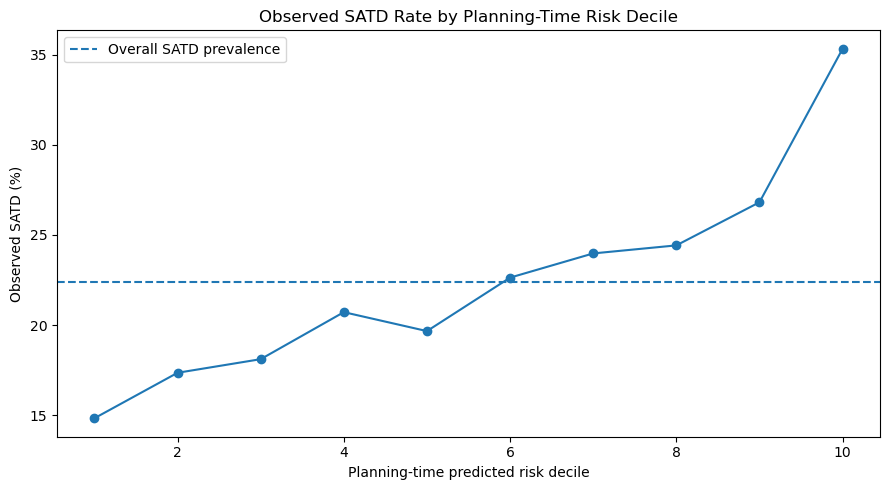

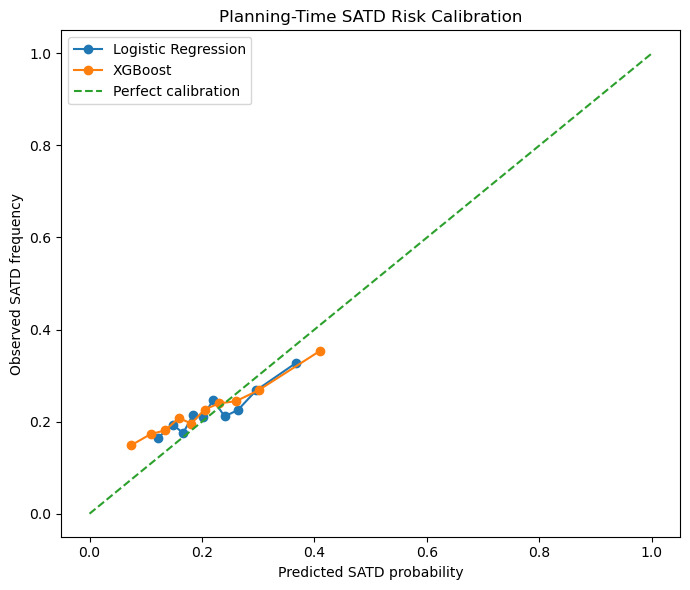

In [29]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(9, 5))
plt.plot(
    risk_deciles["risk_decile"].astype(int),
    risk_deciles["observed_satd_percentage"],
    marker="o"
)
plt.axhline(
    overall_satd_rate * 100,
    linestyle="--",
    label="Overall SATD prevalence"
)
plt.xlabel("Planning-time predicted risk decile")
plt.ylabel("Observed SATD (%)")
plt.title("Observed SATD Rate by Planning-Time Risk Decile")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "risk_decile_plot.png", dpi=300)
plt.show()

prob_true_lr, prob_pred_lr = calibration_curve(
    y, lr_oof, n_bins=10, strategy="quantile"
)
prob_true_xgb, prob_pred_xgb = calibration_curve(
    y, xgb_oof, n_bins=10, strategy="quantile"
)

plt.figure(figsize=(7, 6))
plt.plot(prob_pred_lr, prob_true_lr, marker="o", label="Logistic Regression")
plt.plot(prob_pred_xgb, prob_true_xgb, marker="o", label="XGBoost")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Predicted SATD probability")
plt.ylabel("Observed SATD frequency")
plt.title("Planning-Time SATD Risk Calibration")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "calibration_plot.png", dpi=300)
plt.show()


In [30]:
def prepare_prediction_data(input_df):
    prepared = input_df.copy()
    prepared["log_issue_age"] = np.log1p(
        prepared["issue_age_days_at_sprint_start"].clip(lower=0)
    )
    prepared["log_sprint_issue_count"] = np.log1p(
        prepared["sprint_issue_count"].clip(lower=0)
    )
    return (
        prepared[categorical_features + numeric_features],
        prepared["is_satd"].astype(int),
        prepared["project_id"]
    )

# satd_confidence is the estimated SATD probability; use confidence in the assigned label.
df["label_confidence"] = np.where(
    df["is_satd"] == 1,
    df["satd_confidence"],
    1 - df["satd_confidence"]
)

sensitivity_results = []
for confidence_threshold in [0.70, 0.80, 0.90]:
    high_conf_df = df[
        df["label_confidence"].fillna(0) >= confidence_threshold
    ].copy()
    sensitivity_results.append({
        "confidence_threshold": confidence_threshold,
        "issues": len(high_conf_df),
        "projects": high_conf_df["project_id"].nunique(),
        "satd_rate": high_conf_df["is_satd"].mean()
    })

    if (
        len(high_conf_df) > 0
        and high_conf_df["is_satd"].nunique() == 2
        and high_conf_df["project_id"].nunique() >= 2
    ):
        sensitivity_X, sensitivity_y, sensitivity_groups = prepare_prediction_data(high_conf_df)
        sensitivity_cv = StratifiedGroupKFold(
            n_splits=min(5, sensitivity_groups.nunique()),
            shuffle=True,
            random_state=42
        )
        sensitivity_fold_results, _ = evaluate_group_cv(
            lr_pipeline,
            sensitivity_X,
            sensitivity_y,
            sensitivity_groups,
            sensitivity_cv,
            f"Logistic Regression (confidence >= {confidence_threshold:.2f})"
        )
        sensitivity_results[-1].update({
            "pr_auc": sensitivity_fold_results["pr_auc"].mean(),
            "roc_auc": sensitivity_fold_results["roc_auc"].mean(),
            "pr_auc_lift": sensitivity_fold_results["pr_auc_lift"].mean()
        })

sensitivity_results = pd.DataFrame(sensitivity_results)
print(sensitivity_results)
sensitivity_results.to_csv(
    OUTPUT_DIR / "confidence_sensitivity_summary.csv", index=False
)


   confidence_threshold  issues  projects  satd_rate    pr_auc   roc_auc  \
0                   0.7    6515        25   0.172371  0.254829  0.596998   
1                   0.8    5469        25   0.160907  0.240570  0.607542   
2                   0.9    3448        25   0.171114  0.280156  0.609459   

   pr_auc_lift  
0     1.409137  
1     1.579408  
2     1.473318  


## Project-bootstrap uncertainty and top-10% alert utility

Fold standard deviations are not confidence intervals. This section resamples complete projects, preserving within-project dependence, to obtain 95% confidence intervals for out-of-project prediction metrics. It also reports precision, recall, and lift when a team reviews only the 10% of issues assigned the highest risk.


In [ ]:
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

BOOTSTRAP_REPETITIONS = 2000
TOP_FRACTION = 0.10

def prediction_metrics(data, probability_column, top_fraction=TOP_FRACTION):
    valid_data = data.dropna(subset=[probability_column]).copy()
    observed = valid_data["is_satd"].astype(int).to_numpy()
    probability = valid_data[probability_column].astype(float).to_numpy()
    if np.unique(observed).size < 2:
        return None
    review_count = max(1, int(np.ceil(top_fraction * len(valid_data))))
    selected = np.argsort(-probability, kind="mergesort")[:review_count]
    true_positives = int(observed[selected].sum())
    prevalence = float(observed.mean())
    precision_at_10 = true_positives / review_count
    recall_at_10 = true_positives / observed.sum() if observed.sum() else np.nan
    return {
        "roc_auc": roc_auc_score(observed, probability),
        "pr_auc": average_precision_score(observed, probability),
        "brier": brier_score_loss(observed, probability),
        "reviewed_issues": review_count,
        "captured_satd": true_positives,
        "precision_at_10pct": precision_at_10,
        "recall_at_10pct": recall_at_10,
        "lift_at_10pct": precision_at_10 / prevalence if prevalence else np.nan,
    }

def project_bootstrap(data, probability_column, model_name, repetitions=BOOTSTRAP_REPETITIONS):
    valid_data = data.dropna(subset=[probability_column]).copy()
    projects = valid_data["project_id"].drop_duplicates().to_numpy()
    project_rows = {
        project: valid_data.index[valid_data["project_id"].eq(project)].to_numpy()
        for project in projects
    }
    random = np.random.default_rng(42)
    bootstrap_rows = []
    for _ in range(repetitions):
        sampled_projects = random.choice(projects, size=len(projects), replace=True)
        sampled_indices = np.concatenate([project_rows[project] for project in sampled_projects])
        result = prediction_metrics(valid_data.loc[sampled_indices], probability_column)
        if result is not None:
            bootstrap_rows.append(result)
    bootstrap = pd.DataFrame(bootstrap_rows)
    point = prediction_metrics(valid_data, probability_column)
    summary = []
    for metric in ["roc_auc", "pr_auc", "brier", "precision_at_10pct", "recall_at_10pct", "lift_at_10pct"]:
        summary.append({
            "model": model_name,
            "metric": metric,
            "estimate": point[metric],
            "ci_lower": bootstrap[metric].quantile(0.025),
            "ci_upper": bootstrap[metric].quantile(0.975),
            "successful_bootstraps": len(bootstrap),
        })
    alert = {
        "model": model_name,
        "review_fraction": TOP_FRACTION,
        "reviewed_issues": point["reviewed_issues"],
        "captured_satd": point["captured_satd"],
        "precision_at_10pct": point["precision_at_10pct"],
        "recall_at_10pct": point["recall_at_10pct"],
        "lift_at_10pct": point["lift_at_10pct"],
    }
    return pd.DataFrame(summary), alert

bootstrap_tables = []
alert_rows = []
for model_name, probability_column in [
    ("Logistic Regression", "lr_probability"),
    ("XGBoost", "xgb_probability"),
]:
    bootstrap_summary, alert = project_bootstrap(
        prediction_df, probability_column, model_name
    )
    bootstrap_tables.append(bootstrap_summary)
    alert_rows.append(alert)

prediction_bootstrap_ci = pd.concat(bootstrap_tables, ignore_index=True)
top10_alert_metrics = pd.DataFrame(alert_rows)
prediction_bootstrap_ci.to_csv(OUTPUT_DIR / "prediction_bootstrap_ci.csv", index=False)
top10_alert_metrics.to_csv(OUTPUT_DIR / "top10_alert_metrics.csv", index=False)
print(prediction_bootstrap_ci.round(4).to_string(index=False))
print("\nTop-10% review utility:")
print(top10_alert_metrics.round(4).to_string(index=False))
